In [2]:
import numpy as np
import matplotlib.pylab as plt
import sys
import warnings
warnings.filterwarnings('ignore')
from matplotlib import animation, rc
from scipy.signal import savgol_filter
from scipy.stats import pearsonr
plt.rcParams['figure.dpi']=400
np.set_printoptions(suppress=True,precision=8,linewidth=10000000)

In [3]:
face = np.load('../Mouse Data/face_downsampled.npy')
face_bw = face[:,:,:,0]
del face

SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy').T
SV_norm = np.linalg.norm(SV)
SV_normalized = SV / SV_norm
SV_ortho = np.load('../Mouse Data/svdTemporalComponents_ZYE_ortho.npy')
SV_norm_ortho = np.linalg.norm(SV_ortho)
SV_normalized_ortho = SV_ortho / SV_norm_ortho

Text(0.5, 0.98, 'Correlation Coefficient Matrices')

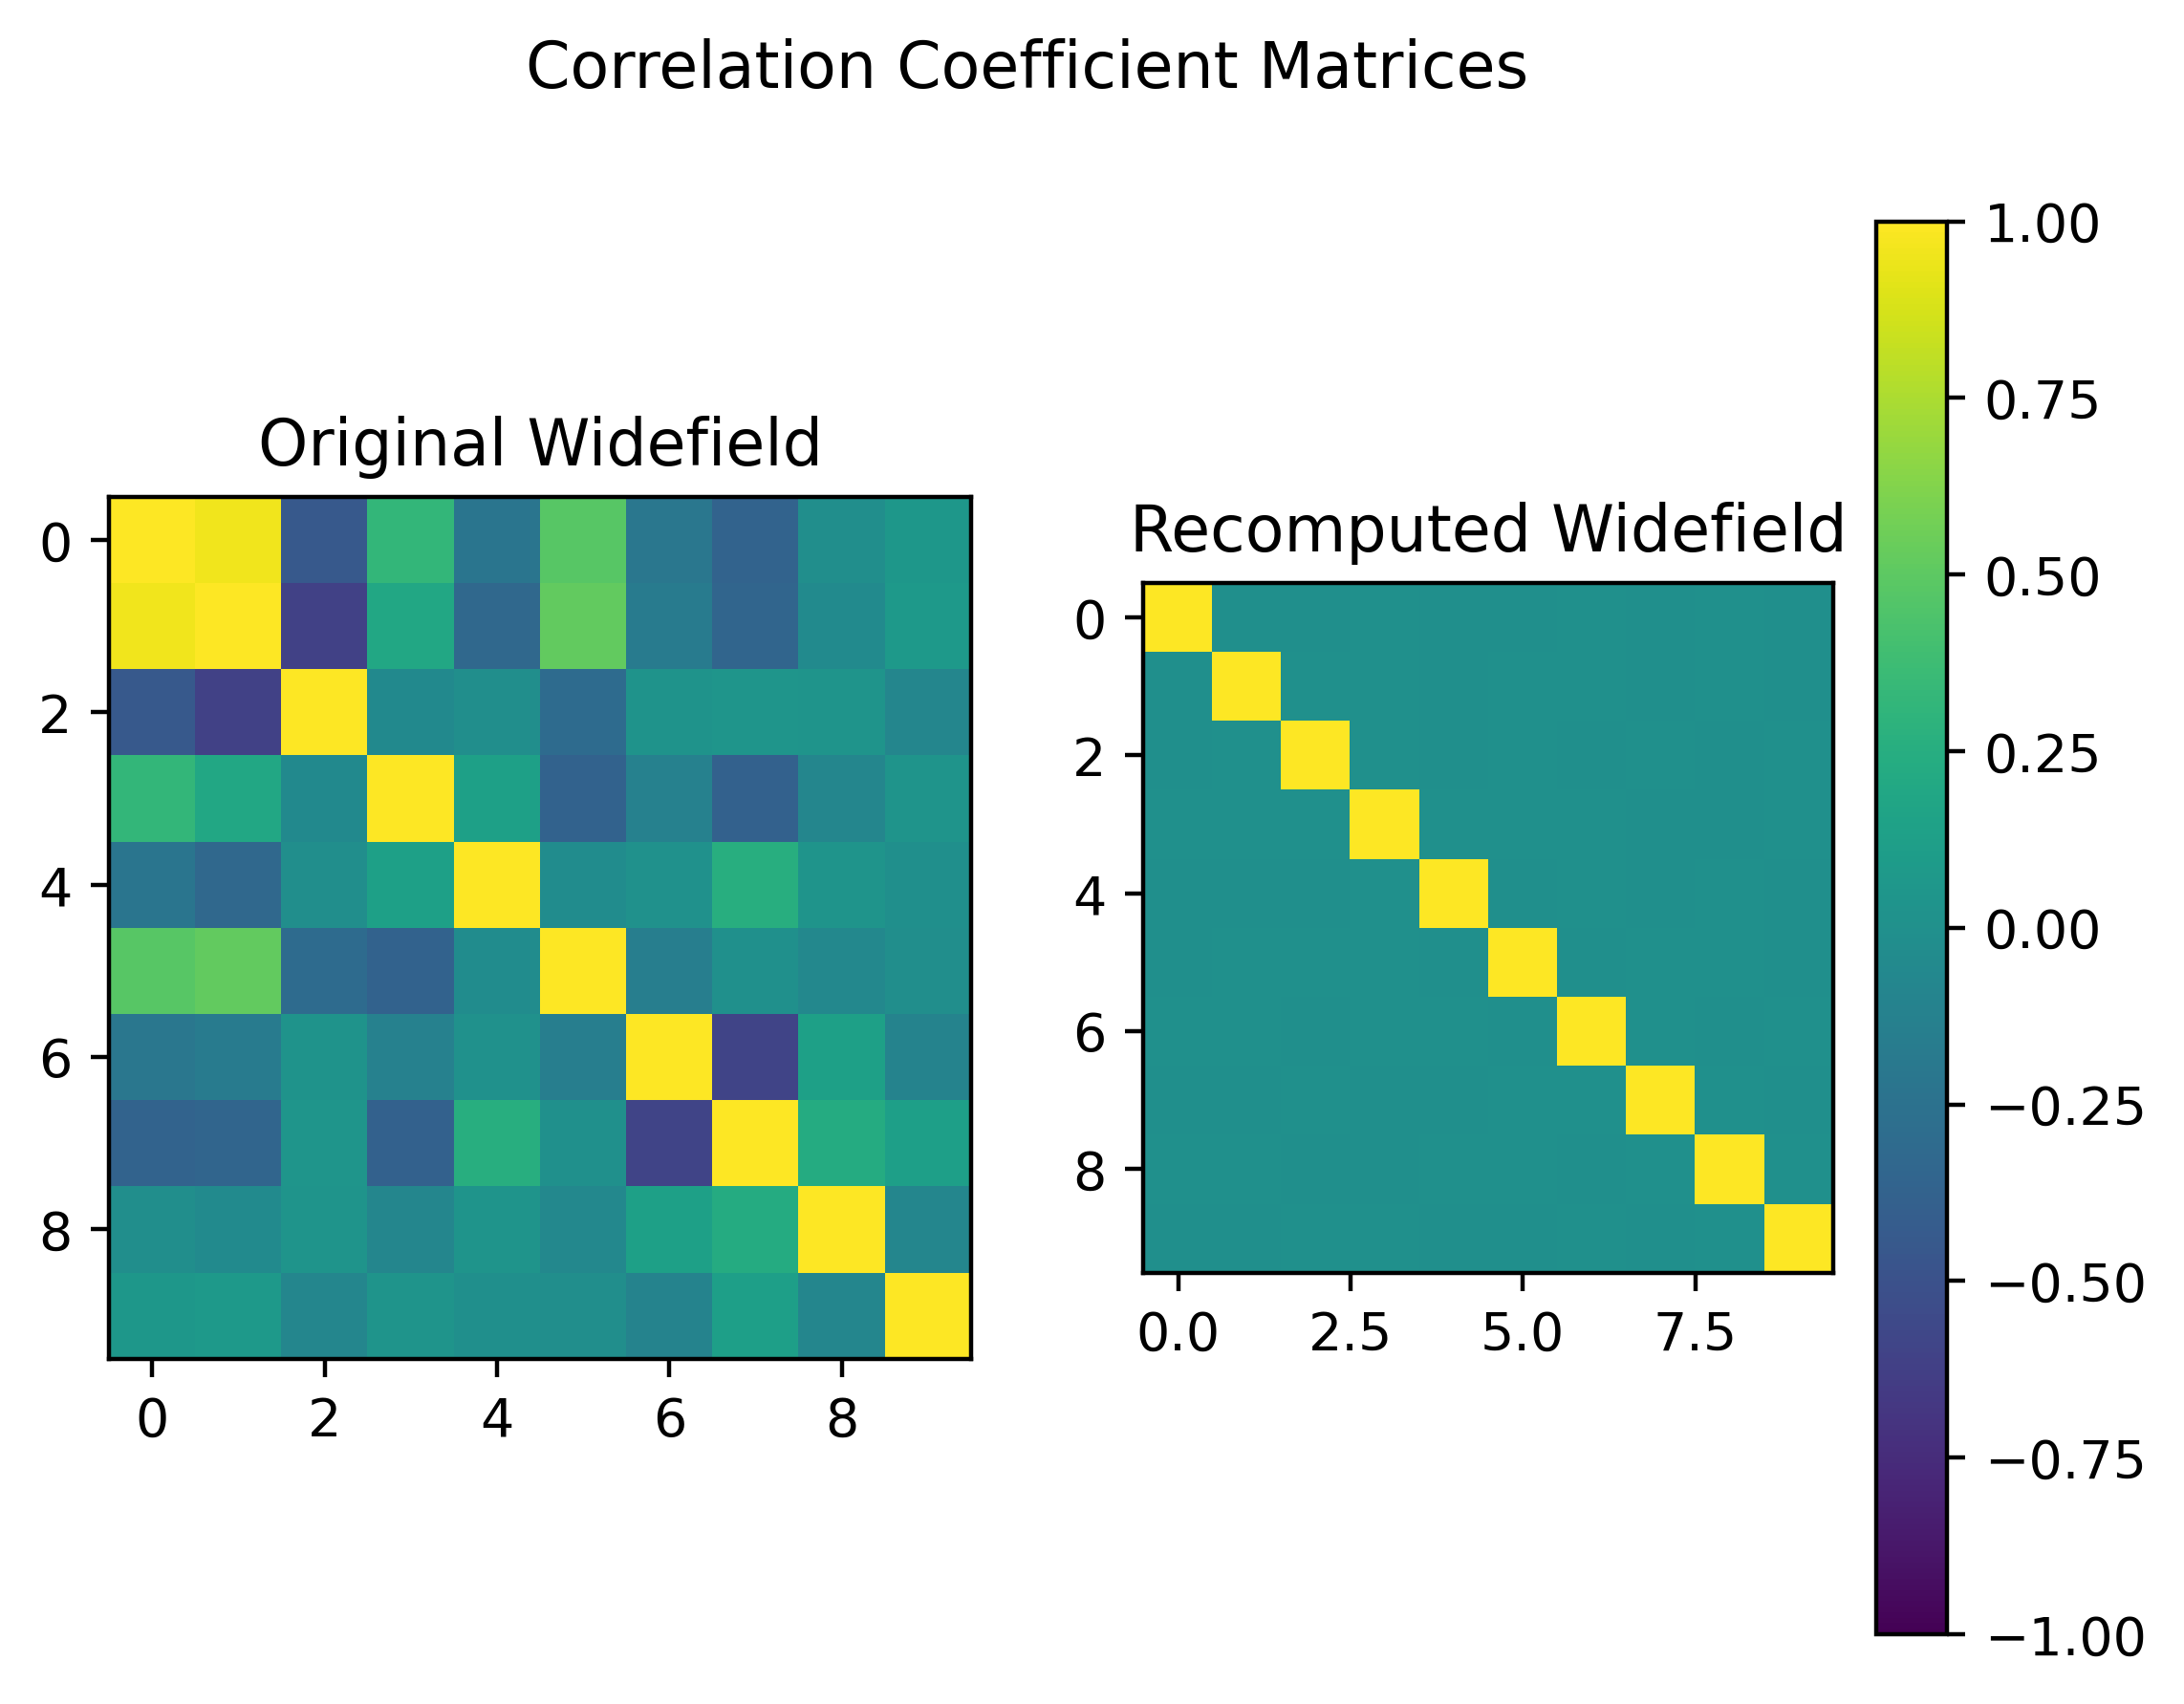

In [7]:
fig,ax = plt.subplots(1,2)
first = ax[0].imshow(np.corrcoef(SV_normalized[:10]),vmin=-1,vmax=1)
ax[0].set_title("Original Widefield")
second = ax[1].imshow(np.corrcoef(SV_normalized_ortho[:10]),vmin=-1,vmax=1)
ax[1].set_title("Recomputed Widefield")
fig.colorbar(second)
fig.suptitle("Correlation Coefficient Matrices")

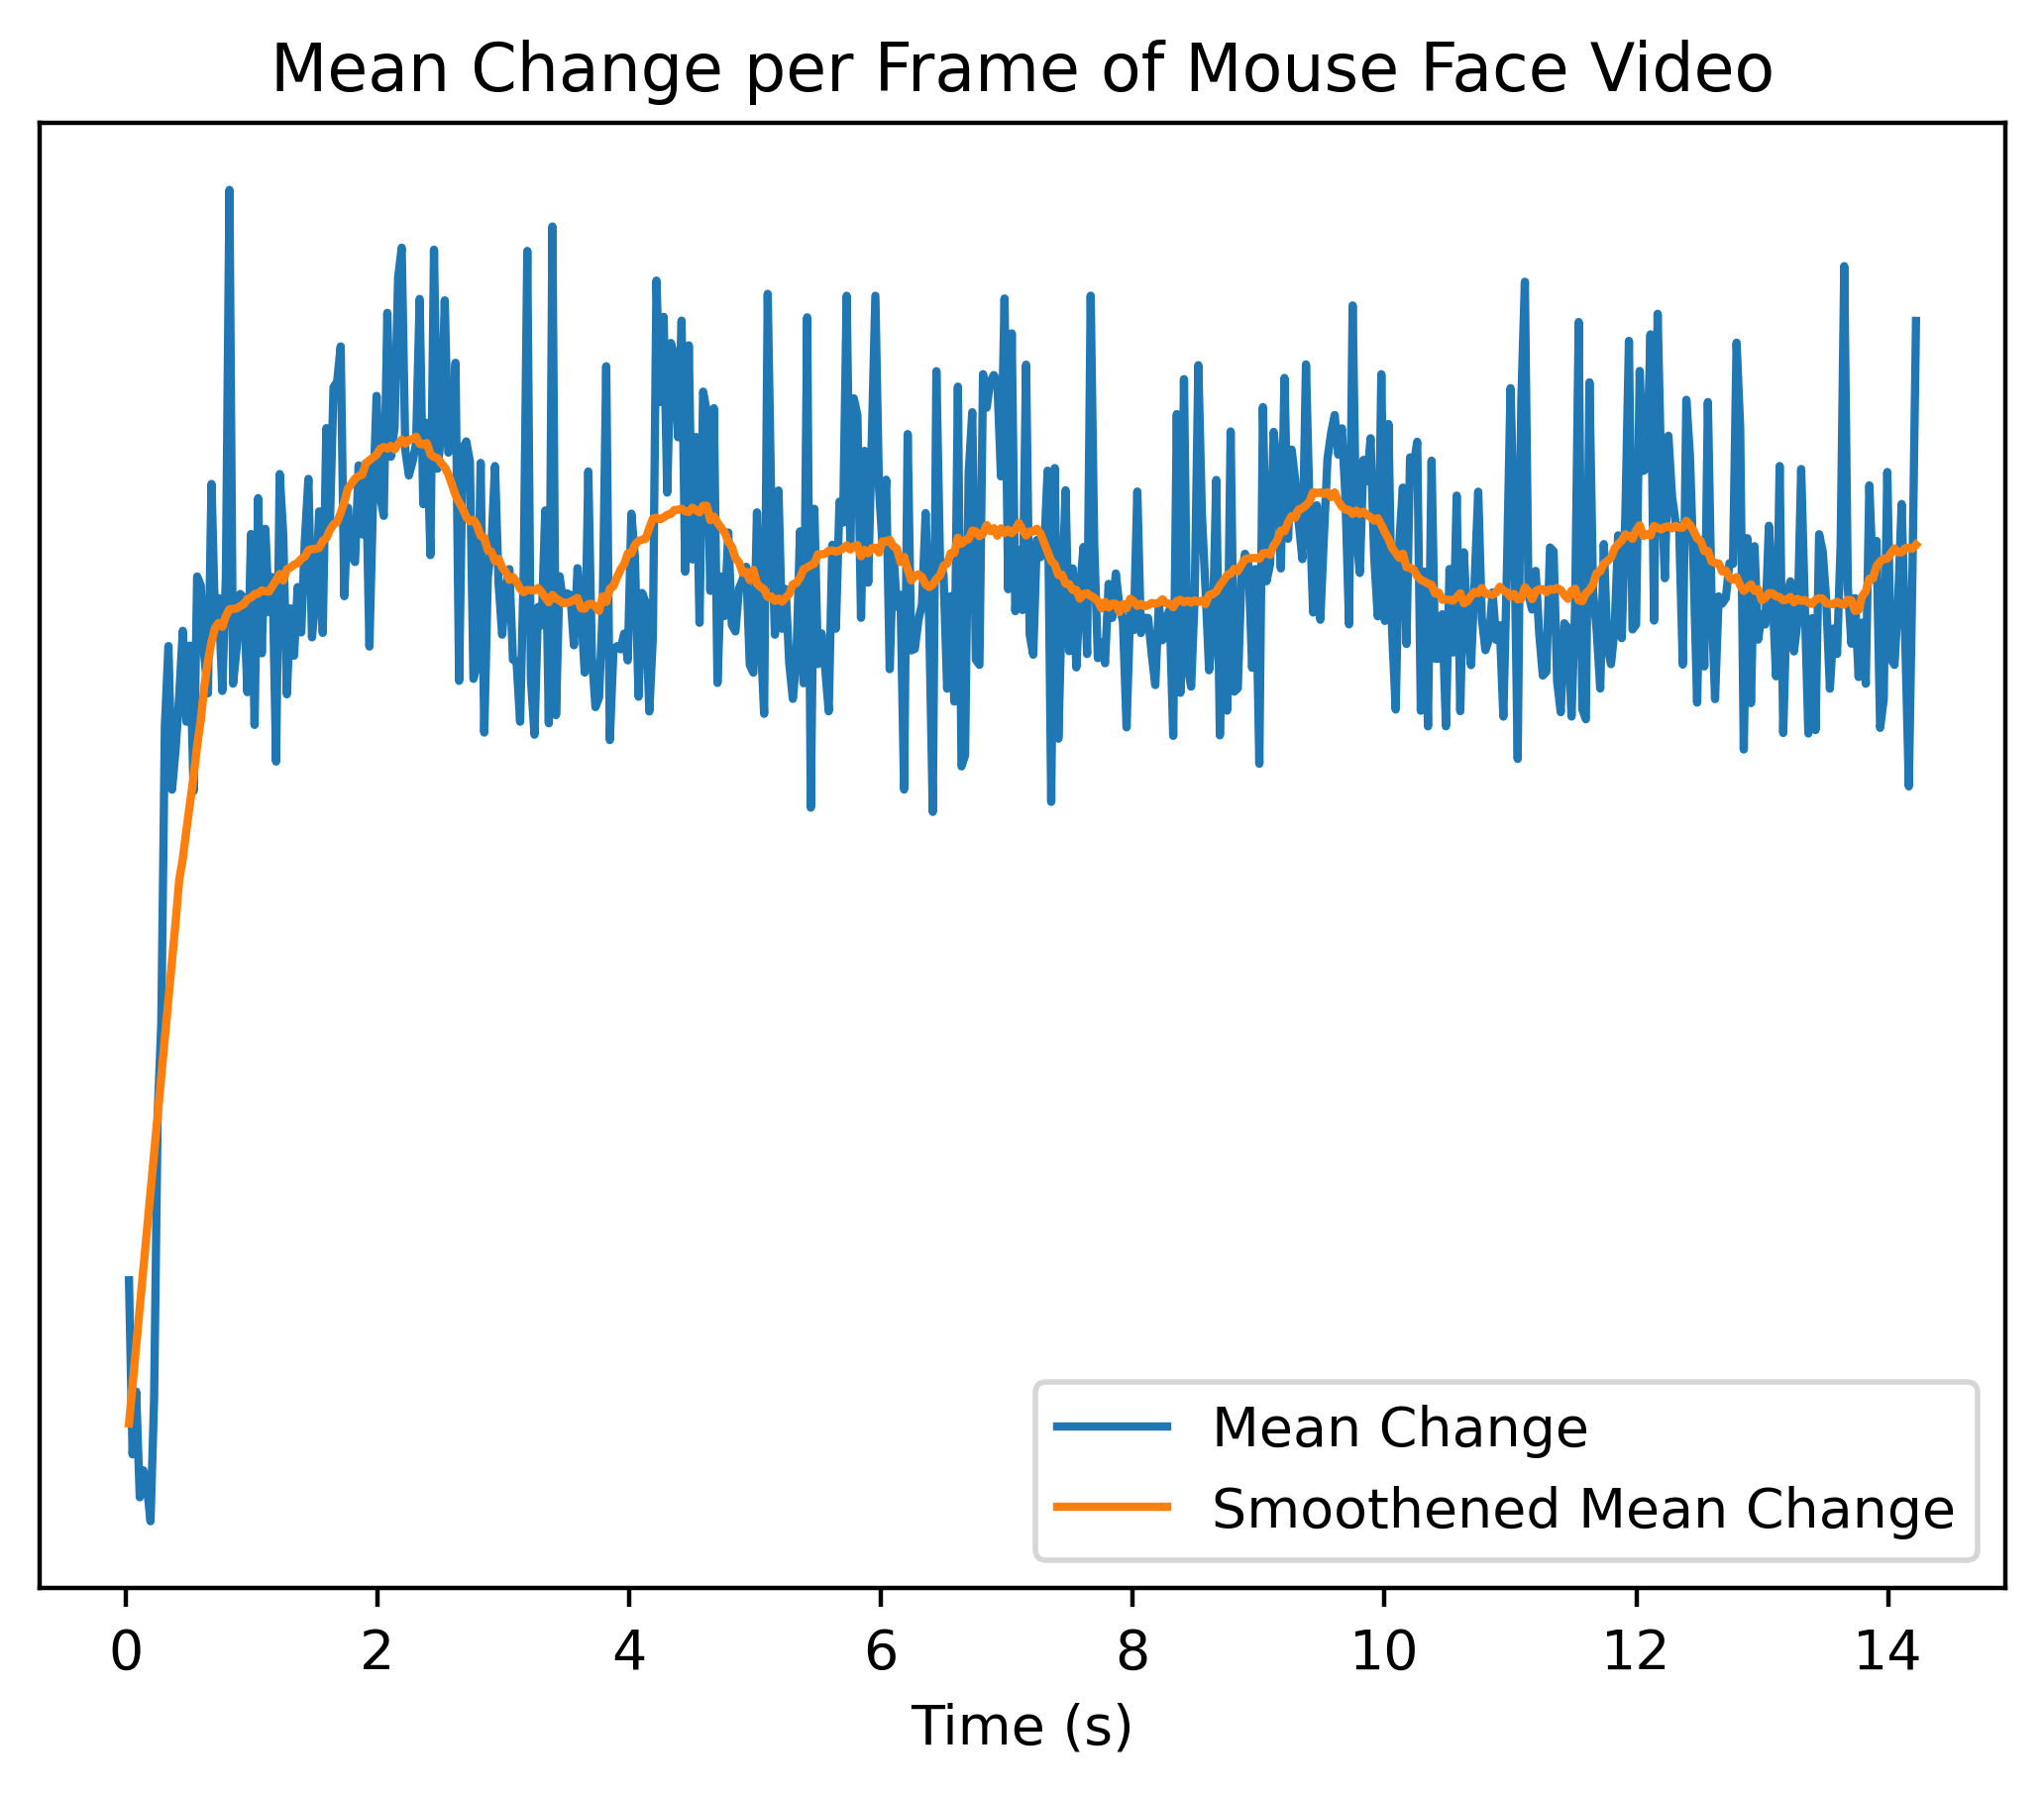

In [5]:
plt.plot(np.arange(1*0.0285,500*0.0285,0.0285),mean_change[1:500],label="Mean Change")
plt.plot(np.arange(1*0.0285,500*0.0285,0.0285),mean_change_smooth[1:500],label="Smoothened Mean Change")
plt.xlabel("Time (s)")
plt.yticks([])
plt.title("Mean Change per Frame of Mouse Face Video")
plt.legend();

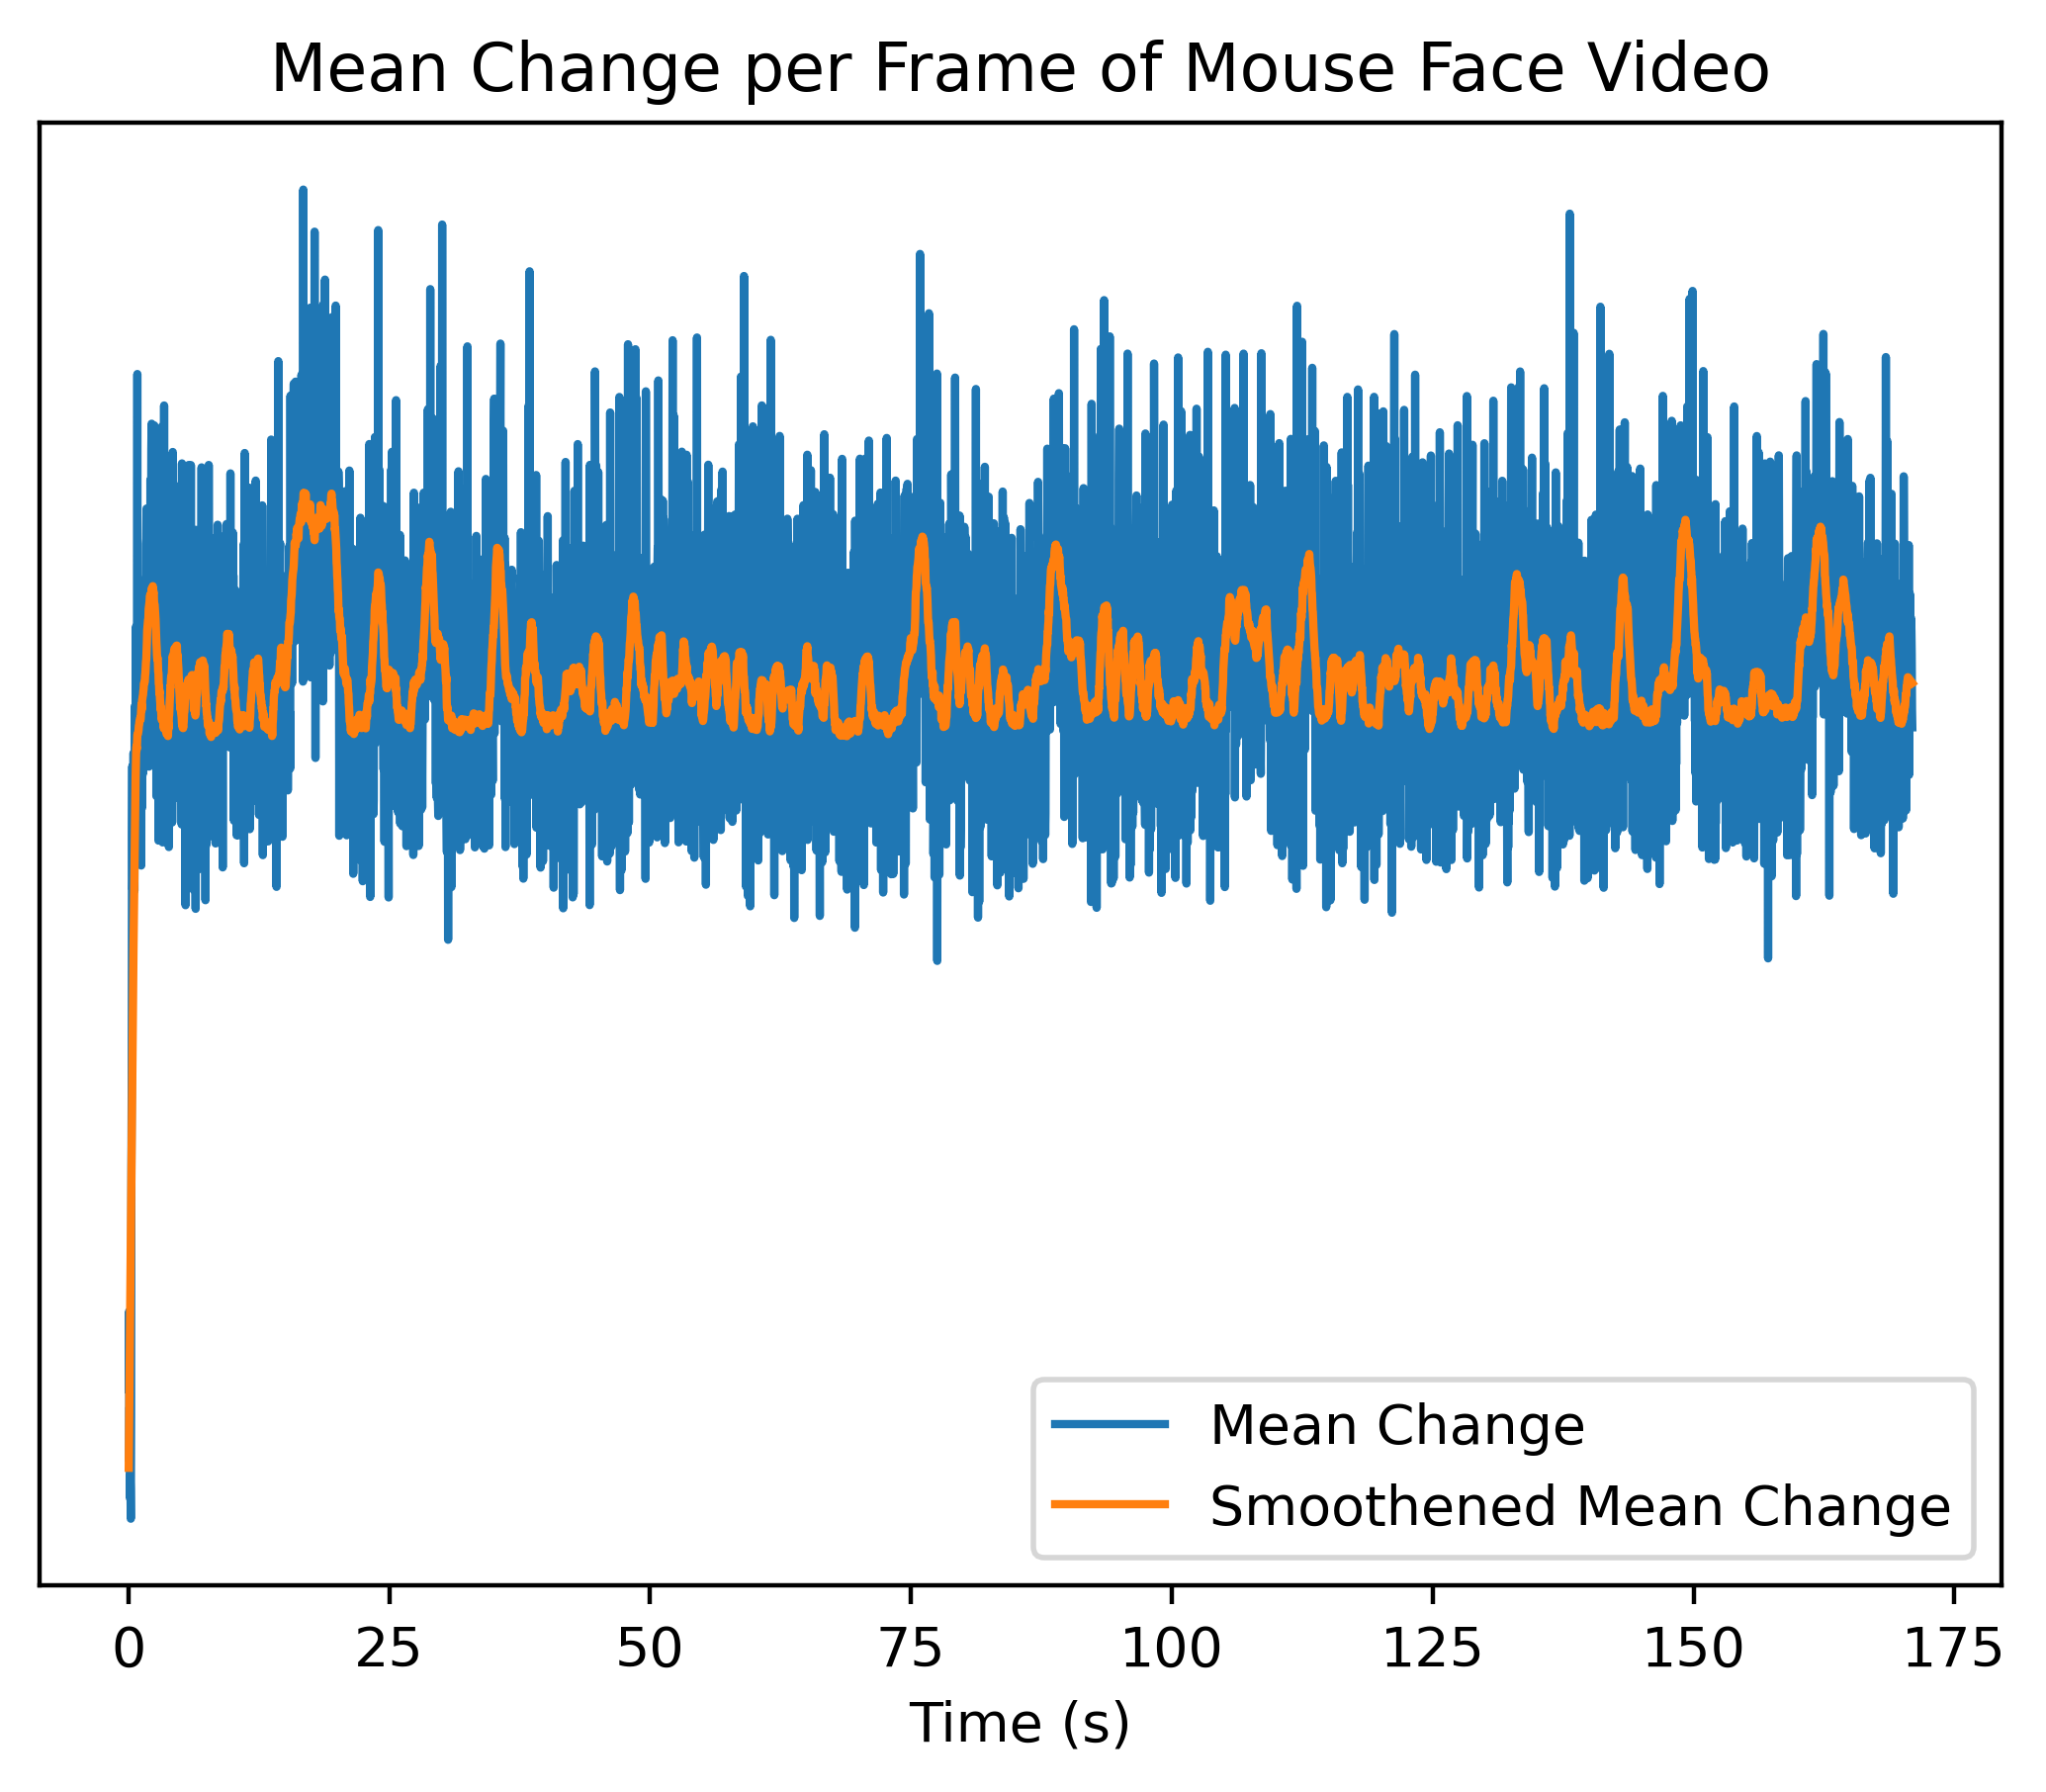

In [4]:
change = np.abs(np.diff(face_bw,axis=0))
mean_change = np.mean(change,axis=(1,2))
mean_change_smooth = savgol_filter(mean_change,30,1)
plt.plot(np.arange(1*0.0285,6000*0.0285,0.0285),mean_change,label="Mean Change")
plt.plot(np.arange(1*0.0285,6000*0.0285,0.0285),mean_change_smooth,label="Smoothened Mean Change")
plt.xlabel("Time (s)")
plt.yticks([])
plt.title("Mean Change per Frame of Mouse Face Video")
plt.legend();

In [4]:
corr_coefs = np.zeros(10)
for i in range(10):
    corr_coefs[i] = pearsonr(mean_change_smooth,SV_normalized[i,1:6000])[0]

corr_coefs_ortho = np.zeros(10)
for i in range(10):
    corr_coefs_ortho[i] = pearsonr(mean_change_smooth,SV_normalized_ortho[i,1:6000])[0]

Text(0.5, 0.98, 'Correlation Coefficients Between SVD Temporal Components and Mouse Movement (3min)')

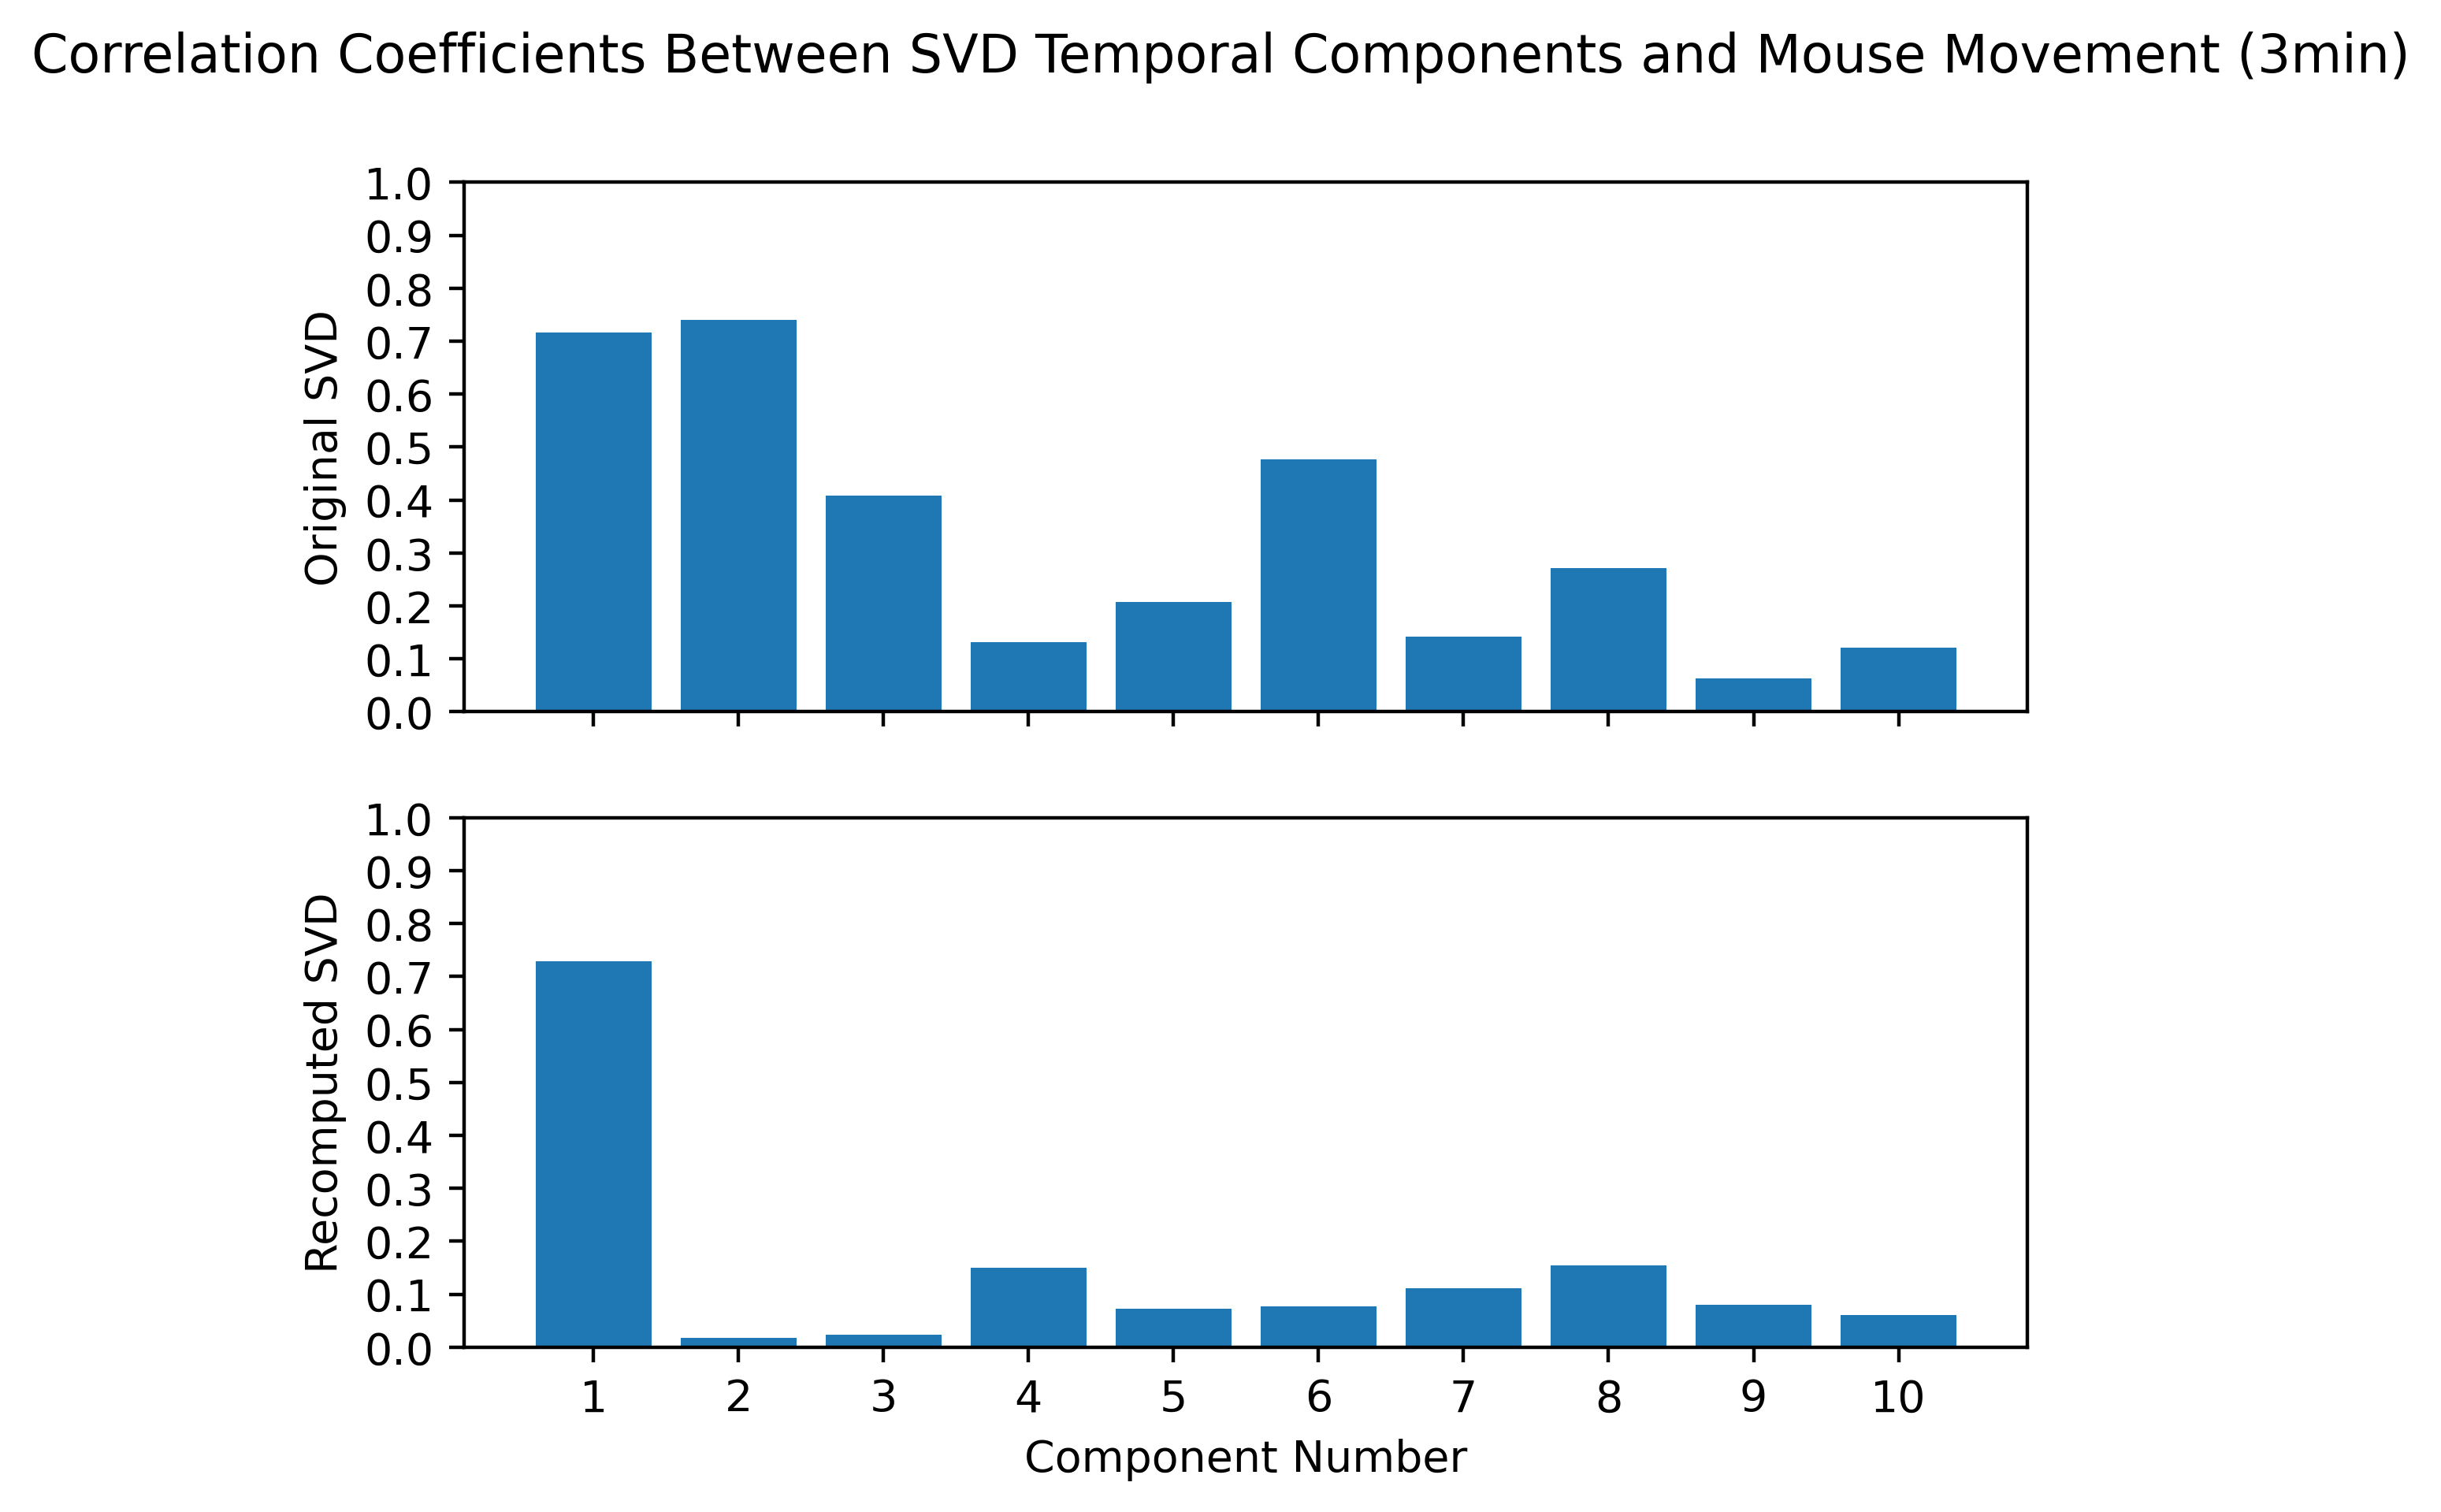

In [5]:
fig,ax = plt.subplots(2,sharex=True,sharey=True)
ax[0].bar(np.arange(1,11),np.abs(corr_coefs))
ax[1].bar(np.arange(1,11),np.abs(corr_coefs_ortho))
ax[1].set_xlabel("Component Number")
ax[1].set_xticks(np.arange(1,11))
ax[0].set_yticks(np.linspace(0,1,11))
ax[0].set_ylabel("Original SVD")
ax[1].set_ylabel("Recomputed SVD")
fig.suptitle("Correlation Coefficients Between SVD Temporal Components and Mouse Movement (3min)")